# Part 1.4: Need today and the Affordable Housing Need Index (AHNI)

This notebook measures **current need** for affordable rental housing in each state and ranks the states. It is a
measurement, not a forecast, and it is never predicted from its own components. The design (agreed in the plan):

| Dimension | Components (higher always means more need) |
|---|---|
| Burden | ACS severe rent burden (2022 to 2024 mean); ACS burden at 30 percent or more; CHAS severe burden among renters at or below 50 percent of area median income |
| Gap | CHAS affordable units per 100 extremely low income renters (inverted); ACS rental vacancy rate (inverted) |
| Pressure | Rent as a share of income (2022 to 2024 mean); rent growth minus income growth, 2021 to 2024 |

Each component is a z-score across the 51 states (capped at plus or minus 3). The headline index weights the three
dimensions equally. Three other weightings test the ranking's sensitivity, and a Monte Carlo redraw of every input within
its margin of error gives each state a rank interval. Homelessness (PIT) is kept out and used to validate the index; the
other policy metrics (assistance coverage, expiring affordability, permit pace) are reported beside the index, not in it.

In [1]:
import sys
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import ahni
from viz import apply_style, SERIES, DIVERGING, SEQUENTIAL, tile_map, save_figure, end_label, SURFACE, INK_2, MUTED, BASELINE, DEEMPHASIS, INK

apply_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

panel = pd.read_csv("data/processed/panel.csv", dtype={"state_fips": str})
snap = pd.read_csv("data/processed/state_snapshot.csv", dtype={"state_fips": str}).set_index("state_abbr")
names = panel.groupby("state_abbr").state_name.first()
est = ahni.build_components(panel)
z = ahni.zscores(est)
dims = ahni.dimension_scores(z)
schemes, loadings, pc_share = ahni.all_schemes(z)
HEAD = "equal dimensions (headline)"
score = schemes[HEAD]
rank = ahni.rank_of(score)
print(f"{len(est)} states, {len(ahni.COMPONENTS)} components; no missing values: {not est.isna().any().any()}")

51 states, 7 components; no missing values: True


## 1. The components

Cross-state spread against the typical sampling error of each component. A component whose between-state SD is many times
its standard error ranks states reliably; one where the two are close does not.

In [2]:
rows = []
for k, (dim, sign, label) in ahni.COMPONENTS.items():
    rows.append({"dimension": dim, "component": label, "mean": est[k].mean(), "SD across states": est[k].std(),
                 "median standard error": est[k + "_se"].median(), "SD / standard error": est[k].std() / est[k + "_se"].median()})
comp_tab = pd.DataFrame(rows)
display(comp_tab.round(2))

,dimension,component,mean,SD across states,median standard error,SD / standard error
0,burden,"ACS severe rent burden, %, mean 2022-24",24.60,2.94,0.41,7.14
1,burden,"ACS rent burden 30%+, %, mean 2022-24",49.41,4.29,0.53,8.17
2,burden,"CHAS severe burden, renters at or below 50% HA...",50.55,6.37,0.54,11.83
3,gap,CHAS affordable units per 100 extremely low in...,63.93,14.30,1.36,10.54
4,gap,"ACS rental vacancy rate, %, mean 2022-24 (inve...",5.40,1.31,0.22,5.89
5,pressure,"ACS rent as % of income, mean 2022-24",19.79,2.57,0.14,19.03
6,pressure,"Rent growth minus income growth, 2021 to 2024,...",4.87,5.53,2.00,2.77


How the oriented components relate to each other (correlations of the z-scores). Components in the same dimension should
hang together; weak links show where a dimension is mixing different things.

In [3]:
short = {"severe_burden_acs": "severe burden ACS", "burden30_acs": "burden 30%+ ACS", "severe_burden_chas_le50": "severe burden CHAS",
         "affordable_units_per100_eli": "few affordable units", "vacancy_rate": "low vacancy", "rent_to_income": "rent to income",
         "rent_minus_income_growth": "rent outgrew income"}
display(z.rename(columns=short).corr().round(2).rename(index=short))
print(f"first principal component explains {pc_share:.0%} of the variance; loadings:")
display(loadings.rename(index=short).round(2).to_frame("PC1 loading").T)

,severe burden ACS,burden 30%+ ACS,severe burden CHAS,few affordable units,low vacancy,rent to income,rent outgrew income
severe burden ACS,1.00,0.95,0.83,0.70,-0.11,0.81,0.07
burden 30%+ ACS,0.95,1.00,0.87,0.71,-0.16,0.88,0.18
severe burden CHAS,0.83,0.87,1.00,0.84,-0.25,0.91,0.12
few affordable units,0.70,0.71,0.84,1.00,0.07,0.71,0.21
low vacancy,-0.11,-0.16,-0.25,0.07,1.00,-0.24,0.22
rent to income,0.81,0.88,0.91,0.71,-0.24,1.00,0.17
rent outgrew income,0.07,0.18,0.12,0.21,0.22,0.17,1.00


first principal component explains 62% of the variance; loadings:


,severe burden ACS,burden 30%+ ACS,severe burden CHAS,few affordable units,low vacancy,rent to income,rent outgrew income
PC1 loading,0.44,0.46,0.46,0.4,-0.09,0.45,0.09


## 2. The ranking, with uncertainty

The dot is the headline rank (1 is the highest need). The line is the 5th to 95th percentile of the rank across 1,000
redraws of every component within its margin of error. Small states have wide intervals.

,state,score,rank,rank 5th pct,rank 95th pct,chance in top 10,burden,gap,pressure
FL,Florida,1.52,1,1.0,1.0,1.00,2.63,-0.12,2.07
NV,Nevada,1.27,2,2.0,3.0,1.00,1.99,0.52,1.29
CA,California,1.22,3,2.0,3.0,1.00,1.57,1.33,0.76
AZ,Arizona,0.93,4,4.0,5.0,1.00,0.87,0.08,1.83
OR,Oregon,0.85,5,4.0,6.0,1.00,1.10,0.94,0.51
NJ,New Jersey,0.80,6,5.0,7.0,1.00,0.71,1.46,0.22
CO,Colorado,0.70,7,6.0,8.0,1.00,0.82,0.82,0.46
NY,New York,0.68,8,7.0,8.0,1.00,0.86,1.01,0.18
GA,Georgia,0.53,9,9.0,13.0,0.60,0.93,-0.27,0.93
VA,Virginia,0.52,10,9.0,13.0,0.45,0.23,0.66,0.66


,state,score,rank,rank 5th pct,rank 95th pct,chance in top 10,burden,gap,pressure
IA,Iowa,-0.86,46,46.0,48.0,0.0,-1.08,-0.31,-1.18
WV,West Virginia,-0.96,47,46.0,48.0,0.0,-0.45,-1.26,-1.16
AK,Alaska,-1.07,48,46.0,49.0,0.0,-1.24,-0.51,-1.45
WY,Wyoming,-1.39,49,48.0,51.0,0.0,-1.60,-1.06,-1.52
SD,South Dakota,-1.56,50,49.0,51.0,0.0,-2.15,-1.59,-0.94
ND,North Dakota,-1.68,51,49.0,51.0,0.0,-2.16,-1.40,-1.47


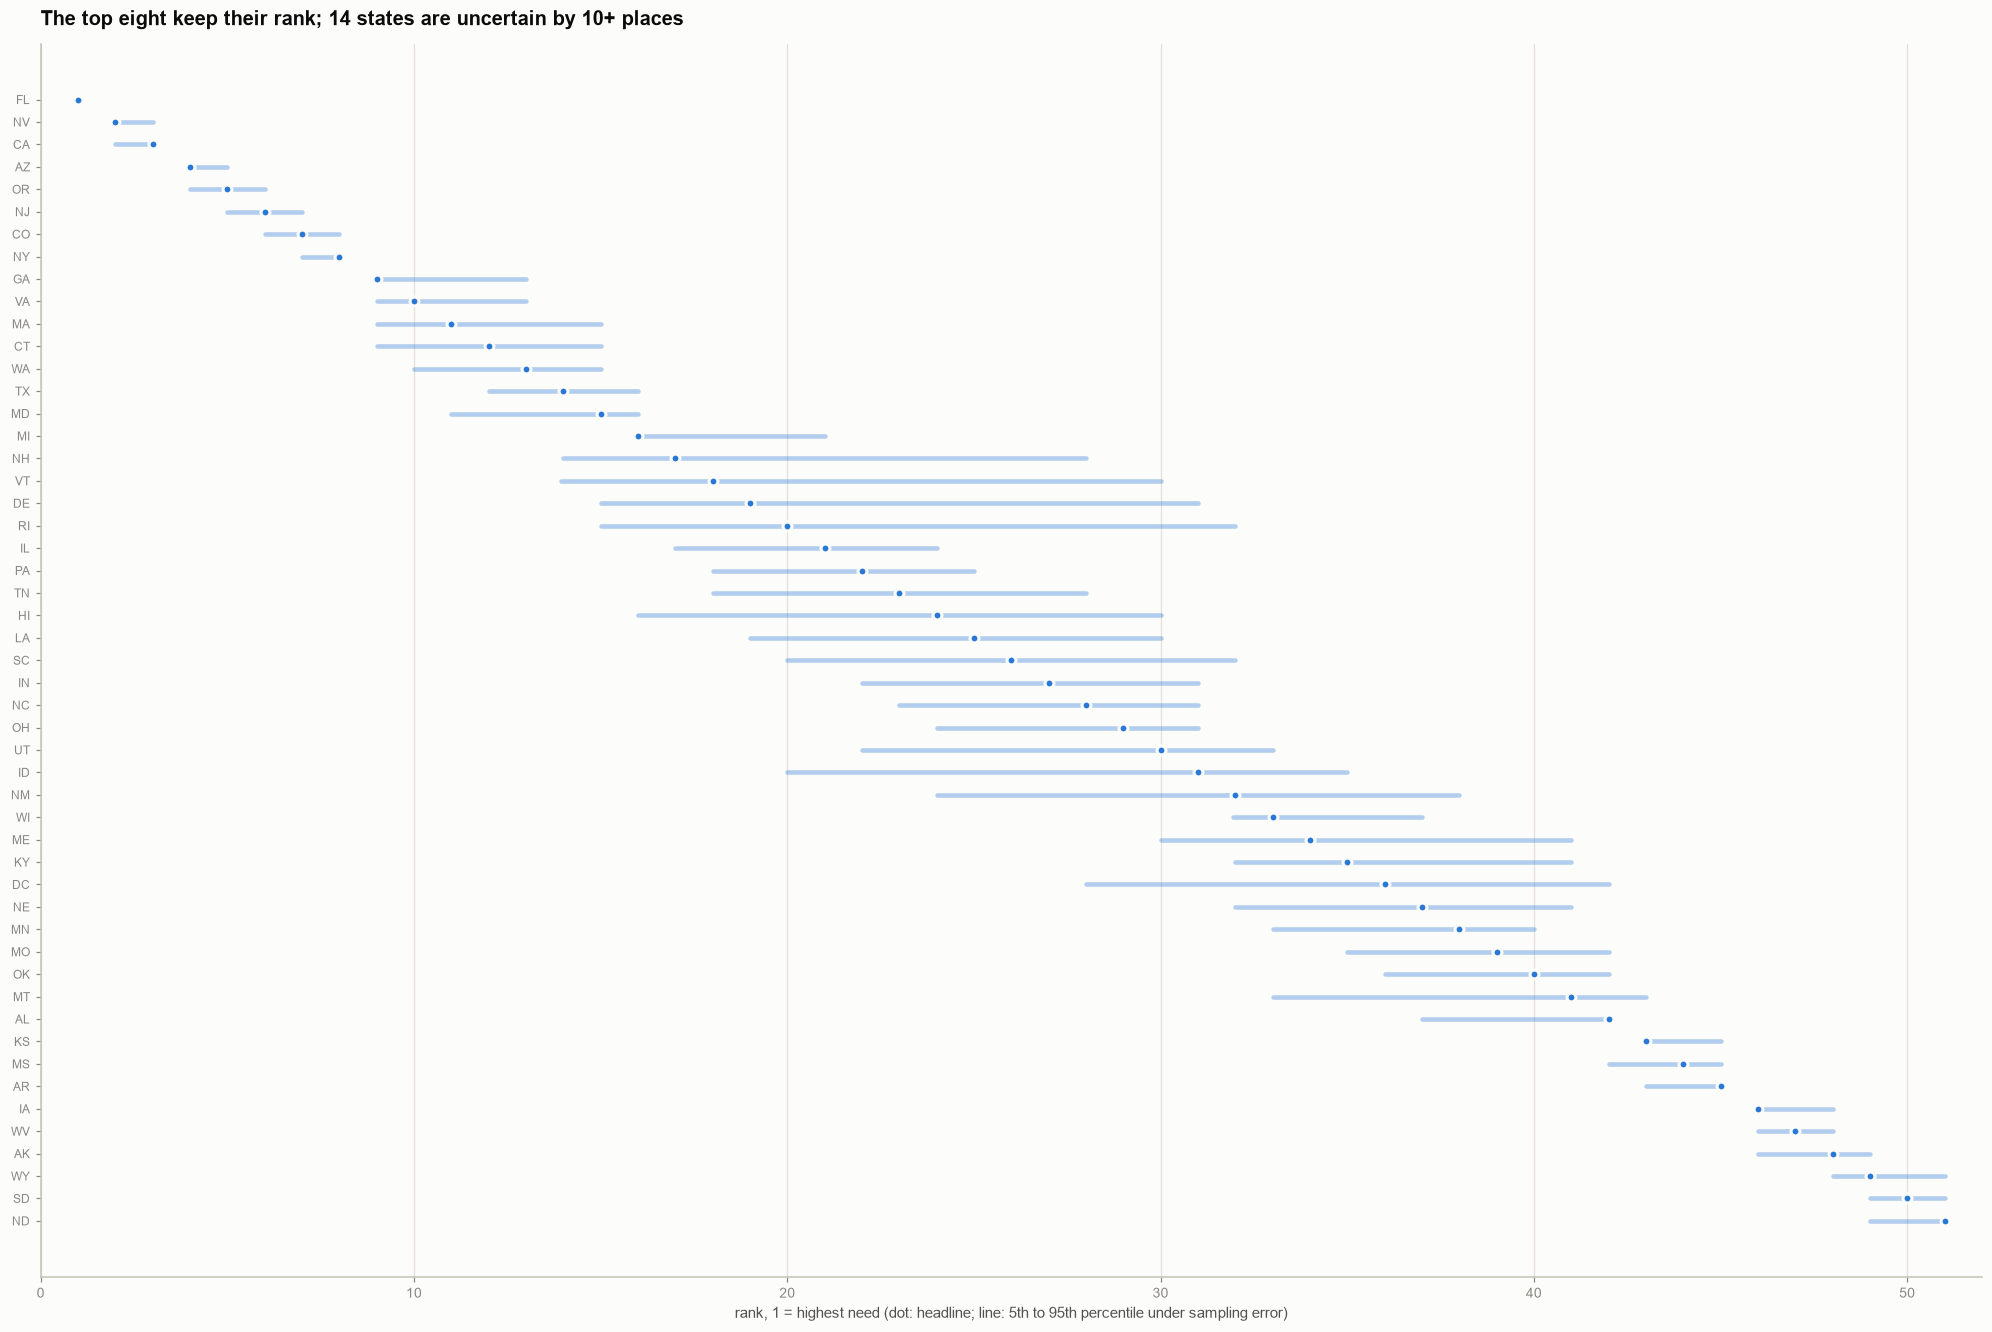

In [4]:
mc = ahni.monte_carlo(est, n=1000)
lo, hi = mc.quantile(.05), mc.quantile(.95)
top10 = (mc <= 10).mean()
table = pd.DataFrame({"state": names, "score": score, "rank": rank, "rank 5th pct": lo, "rank 95th pct": hi, "chance in top 10": top10,
                      "burden": dims.burden, "gap": dims.gap, "pressure": dims.pressure}).sort_values("rank")
display(table.head(12).round(2))
display(table.tail(6).round(2))

order = table.index.tolist()
fig, ax = plt.subplots(figsize=(18, 12))
y = np.arange(len(order))[::-1]
for yi, st in zip(y, order):
    ax.plot([table.loc[st, "rank 5th pct"], table.loc[st, "rank 95th pct"]], [yi, yi], color=SERIES[0], alpha=0.35, lw=3, solid_capstyle="round", zorder=2)
ax.scatter(table["rank"], y, s=34, color=SERIES[0], edgecolor=SURFACE, linewidth=2, zorder=3)
ax.set_yticks(y, order, fontsize=8)
ax.set_xlabel("rank, 1 = highest need (dot: headline; line: 5th to 95th percentile under sampling error)")
ax.set_xlim(0, 52)
ax.grid(axis="y", visible=False)
width = table["rank 95th pct"] - table["rank 5th pct"]
ax.set_title(f"The top eight keep their rank; {int((width >= 10).sum())} states are uncertain by 10+ places")
save_figure(fig, "04_ahni_rank_intervals")
plt.show()

## 3. Where the need is

Headline score by state on a tile map (each state one equal square at an approximate position).

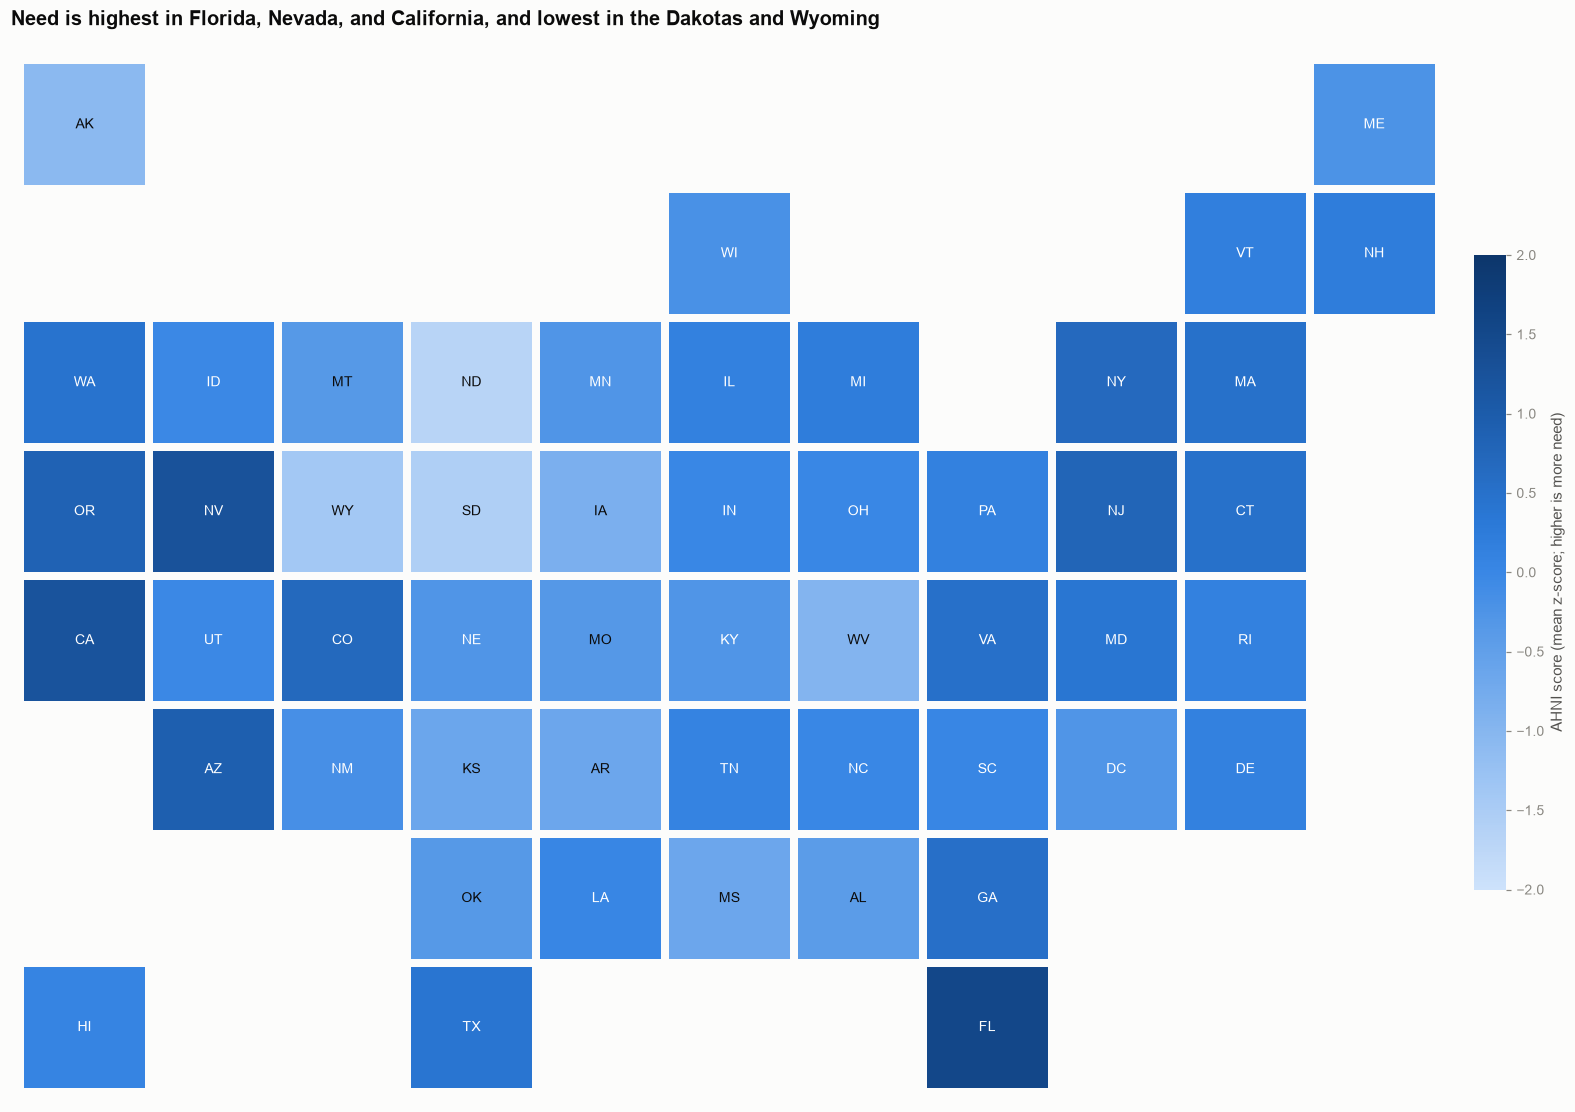

In [5]:
fig, ax = plt.subplots(figsize=(18, 10))
sm = tile_map(ax, score, vmin=-2, vmax=2)
cb = fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.01)
cb.set_label("AHNI score (mean z-score; higher is more need)", color=INK_2)
cb.outline.set_visible(False)
ax.set_title("Need is highest in Florida, Nevada, and California, and lowest in the Dakotas and Wyoming")
save_figure(fig, "04_ahni_tile_map")
plt.show()

What drives each state's score: z-scores of the seven components, states ordered from highest to lowest need. Red is
more need than the average state, blue less, gray about average.

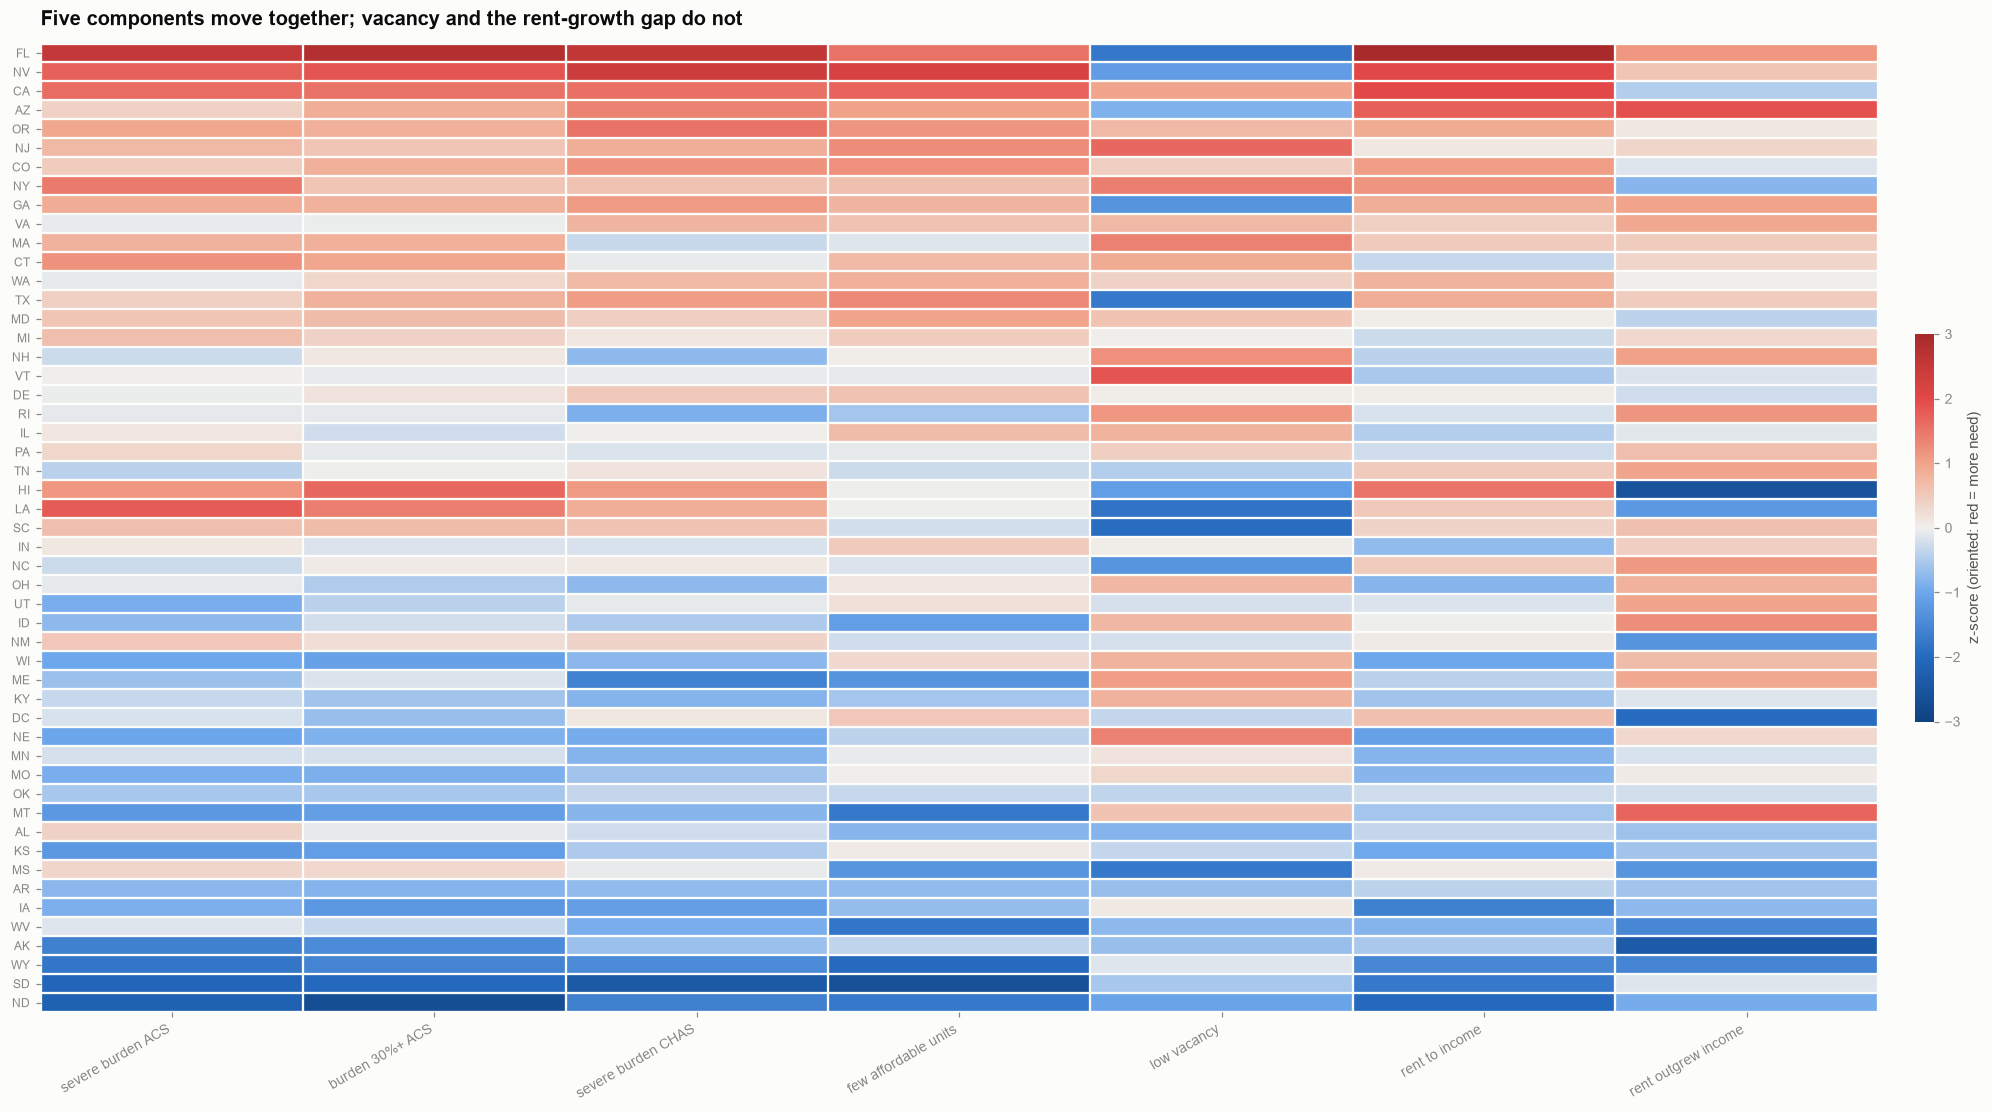

In [6]:
prof = z.loc[order].rename(columns=short)
fig, ax = plt.subplots(figsize=(18, 10))
im = ax.imshow(prof.values, aspect="auto", cmap=DIVERGING, vmin=-3, vmax=3)
ax.set_xticks(range(prof.shape[1]), prof.columns, rotation=30, ha="right", fontsize=9)
ax.set_yticks(range(prof.shape[0]), prof.index, fontsize=8)
ax.set_xticks(np.arange(-.5, prof.shape[1], 1), minor=True); ax.set_yticks(np.arange(-.5, prof.shape[0], 1), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=1.5); ax.grid(which="major", visible=False)
ax.tick_params(which="minor", length=0)
for s_ in ax.spines.values():
    s_.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.4, pad=0.02); cb.set_label("z-score (oriented: red = more need)", color=INK_2); cb.outline.set_visible(False)
ax.set_title("Five components move together; vacancy and the rent-growth gap do not")
save_figure(fig, "04_ahni_component_profiles")
plt.show()

## 4. How sensitive is the ranking?

Four weightings of the same components. Spearman rank correlations between schemes, then how many of the headline's top ten
each other scheme keeps.

In [7]:
rk = schemes.apply(ahni.rank_of)
display(schemes.corr(method="spearman").round(3))
top_head = set(rk[HEAD][rk[HEAD] <= 10].index)
overlap = pd.DataFrame({"states in headline top 10 also in top 10": {c: len(top_head & set(rk[c][rk[c] <= 10].index)) for c in rk.columns}})
display(overlap)
spread = (rk.max(axis=1) - rk.min(axis=1)).rename("rank spread across schemes")
display(pd.concat([rk[HEAD].rename("headline rank"), spread], axis=1).sort_values("rank spread across schemes", ascending=False).head(8).assign(state=lambda d: d.index.map(names)))

,equal dimensions (headline),"expert (burden 50, gap 30, pressure 20)",equal components,first principal component
equal dimensions (headline),1.000,0.980,0.988,0.878
"expert (burden 50, gap 30, pressure 20)",0.980,1.000,0.996,0.934
equal components,0.988,0.996,1.000,0.926
first principal component,0.878,0.934,0.926,1.000


,states in headline top 10 also in top 10
equal dimensions (headline),10
"expert (burden 50, gap 30, pressure 20)",9
equal components,9
first principal component,7


,headline rank,rank spread across schemes,state
HI,24,18,Hawaii
LA,25,16,Louisiana
MS,44,16,Mississippi
NH,17,15,New Hampshire
RI,20,13,Rhode Island
SC,26,13,South Carolina
AL,42,13,Alabama
DC,36,12,District of Columbia


Dropping one component at a time (equal weight across the remaining dimensions):

In [8]:
loo = ahni.leave_one_out(est, rank).assign(component=lambda d: d.dropped.map(short)).drop(columns="dropped").set_index("component")
display(loo.round(3))

,rank correlation with headline,largest rank change,states in top 10 unchanged
component,,,
severe burden ACS,0.993,5,10
burden 30%+ ACS,0.995,5,10
severe burden CHAS,0.993,5,8
few affordable units,0.910,18,8
low vacancy,0.948,13,9
rent to income,0.943,18,9
rent outgrew income,0.945,17,8


## 5. Validation: does the index track homelessness?

Homelessness is not in the index. The point-in-time count per 10,000 residents, averaged over 2022 and 2023 (both complete
years), is an independent outcome. A state with high need should tend to have a high homelessness rate, though homelessness
also depends on climate, shelter policy, and who gets counted.

Spearman correlation of AHNI score with the PIT rate: 0.34 (without DC: 0.38)


,severe burden ACS,burden 30%+ ACS,severe burden CHAS,few affordable units,low vacancy,rent to income,rent outgrew income
Spearman with PIT rate,0.16,0.25,0.25,0.22,0.26,0.41,-0.02


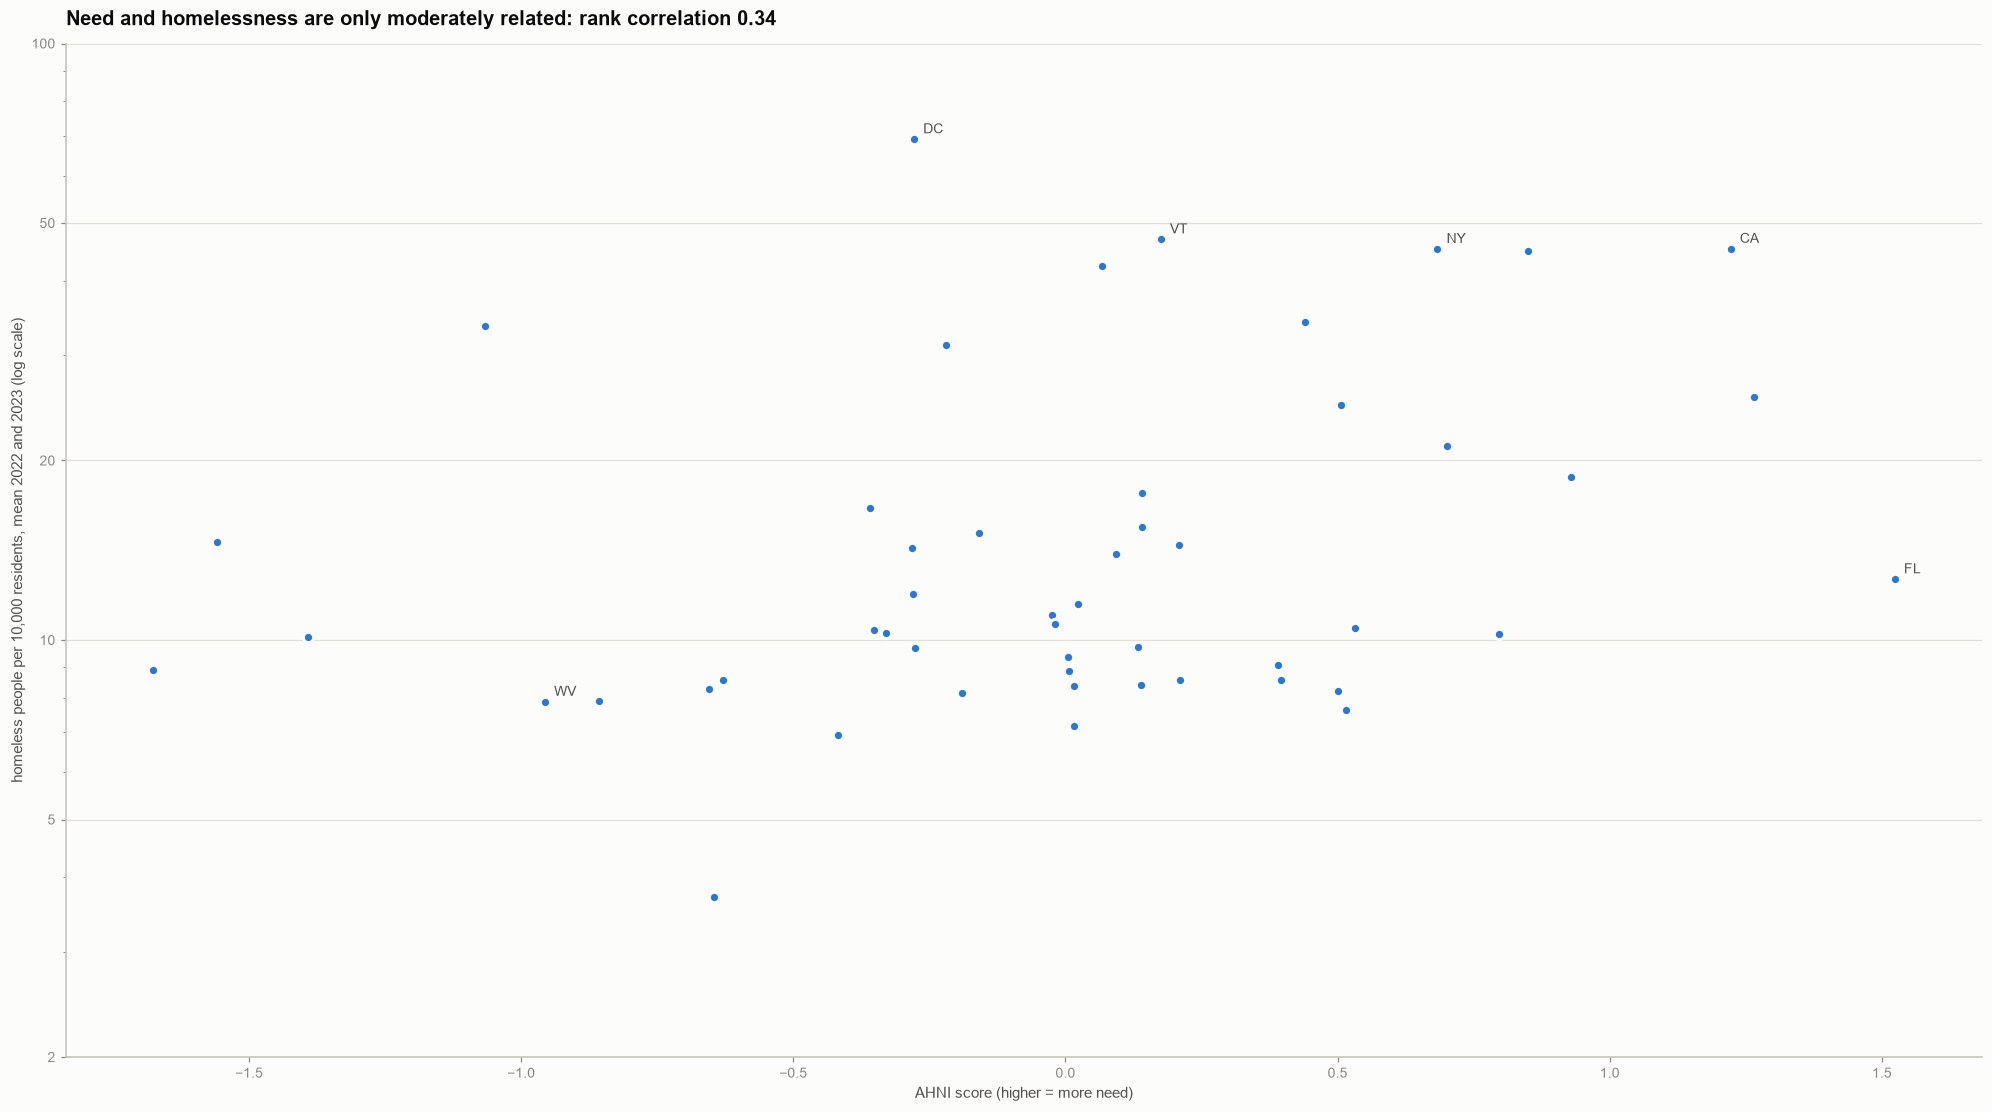

In [9]:
pit = panel[panel.year.isin([2022, 2023])].groupby("state_abbr").pit_rate_per_10k.mean()
chk = pd.DataFrame({"score": score, "pit": pit})
rho = chk.score.corr(chk.pit, method="spearman")
rho_x = chk.drop("DC").score.corr(chk.drop("DC").pit, method="spearman")
comp_rho = pd.Series({short[k]: z[k].corr(pit, method="spearman") for k in ahni.COMPONENTS}).round(2)
print(f"Spearman correlation of AHNI score with the PIT rate: {rho:.2f} (without DC: {rho_x:.2f})")
display(comp_rho.to_frame("Spearman with PIT rate").T)

fig, ax = plt.subplots(figsize=(18, 10))
ax.scatter(chk.score, chk.pit, s=46, color=SERIES[0], edgecolor=SURFACE, linewidth=2, zorder=3)
ax.set_yscale("log")
ax.set_yticks([2, 5, 10, 20, 50, 100], ["2", "5", "10", "20", "50", "100"])
ax.set_xlabel("AHNI score (higher = more need)")
ax.set_ylabel("homeless people per 10,000 residents, mean 2022 and 2023 (log scale)")
ax.grid(axis="x", visible=False)
ax.set_title(f"Need and homelessness are only moderately related: rank correlation {rho:.2f}")
for st in list(chk.pit.nlargest(4).index) + ["FL", "WV"]:
    ax.annotate(st, (chk.score[st], chk.pit[st]), xytext=(6, 4), textcoords="offset points", fontsize=9, color=INK_2)
save_figure(fig, "04_ahni_vs_homelessness")
plt.show()

## 6. The other policy metrics, beside the index

How much is needed (the index, with the affordable-unit gap inside it), how much is at risk, and how fast states are
building. These are not part of the score.

* **Assistance coverage:** HUD-assisted units (2022, excludes LIHTC) per 100 renter households at or below 50 percent of area
  median income (CHAS 2018-2022, ending 2022)
* **Expiring affordability:** share of active NHPD units in properties whose last subsidy ends by 2035 (upper bound: counts
  all units in those properties) and the lower bound from the largest subsidy per property
* **Supply pace:** permitted units in buildings of 5 or more, mean of 2022 to 2024, per 1,000 renter households (ACS); and per
  new renter household 2021 to 2024 where renter households grew

,state,AHNI score,AHNI rank,assisted units per 100 eligible renters,% of active NHPD units losing last subsidy by 2035 (upper),(lower bound),"5+ unit permits per 1,000 renter hh (2022-24 mean)","5+ unit permits per new renter hh, 2022-24"
FL,Florida,1.52,1,20.08,13.35,12.21,21.39,1.44
NV,Nevada,1.27,2,14.58,19.42,17.47,11.31,2.26
CA,California,1.22,3,21.34,13.43,11.39,7.48,0.80
AZ,Arizona,0.93,4,13.82,26.46,23.04,20.64,1.17
OR,Oregon,0.85,5,24.66,14.74,12.69,10.53,0.76
NJ,New Jersey,0.80,6,31.46,17.15,15.50,15.32,1.70
CO,Colorado,0.70,7,21.33,22.20,17.77,21.58,0.68
NY,New York,0.68,8,36.81,17.58,13.14,7.17,0.48
GA,Georgia,0.53,9,25.51,22.86,18.30,15.25,1.02
VA,Virginia,0.52,10,26.18,27.41,24.36,12.95,0.79


states where renter households did not grow 2021 to 2024 (no ratio): 3


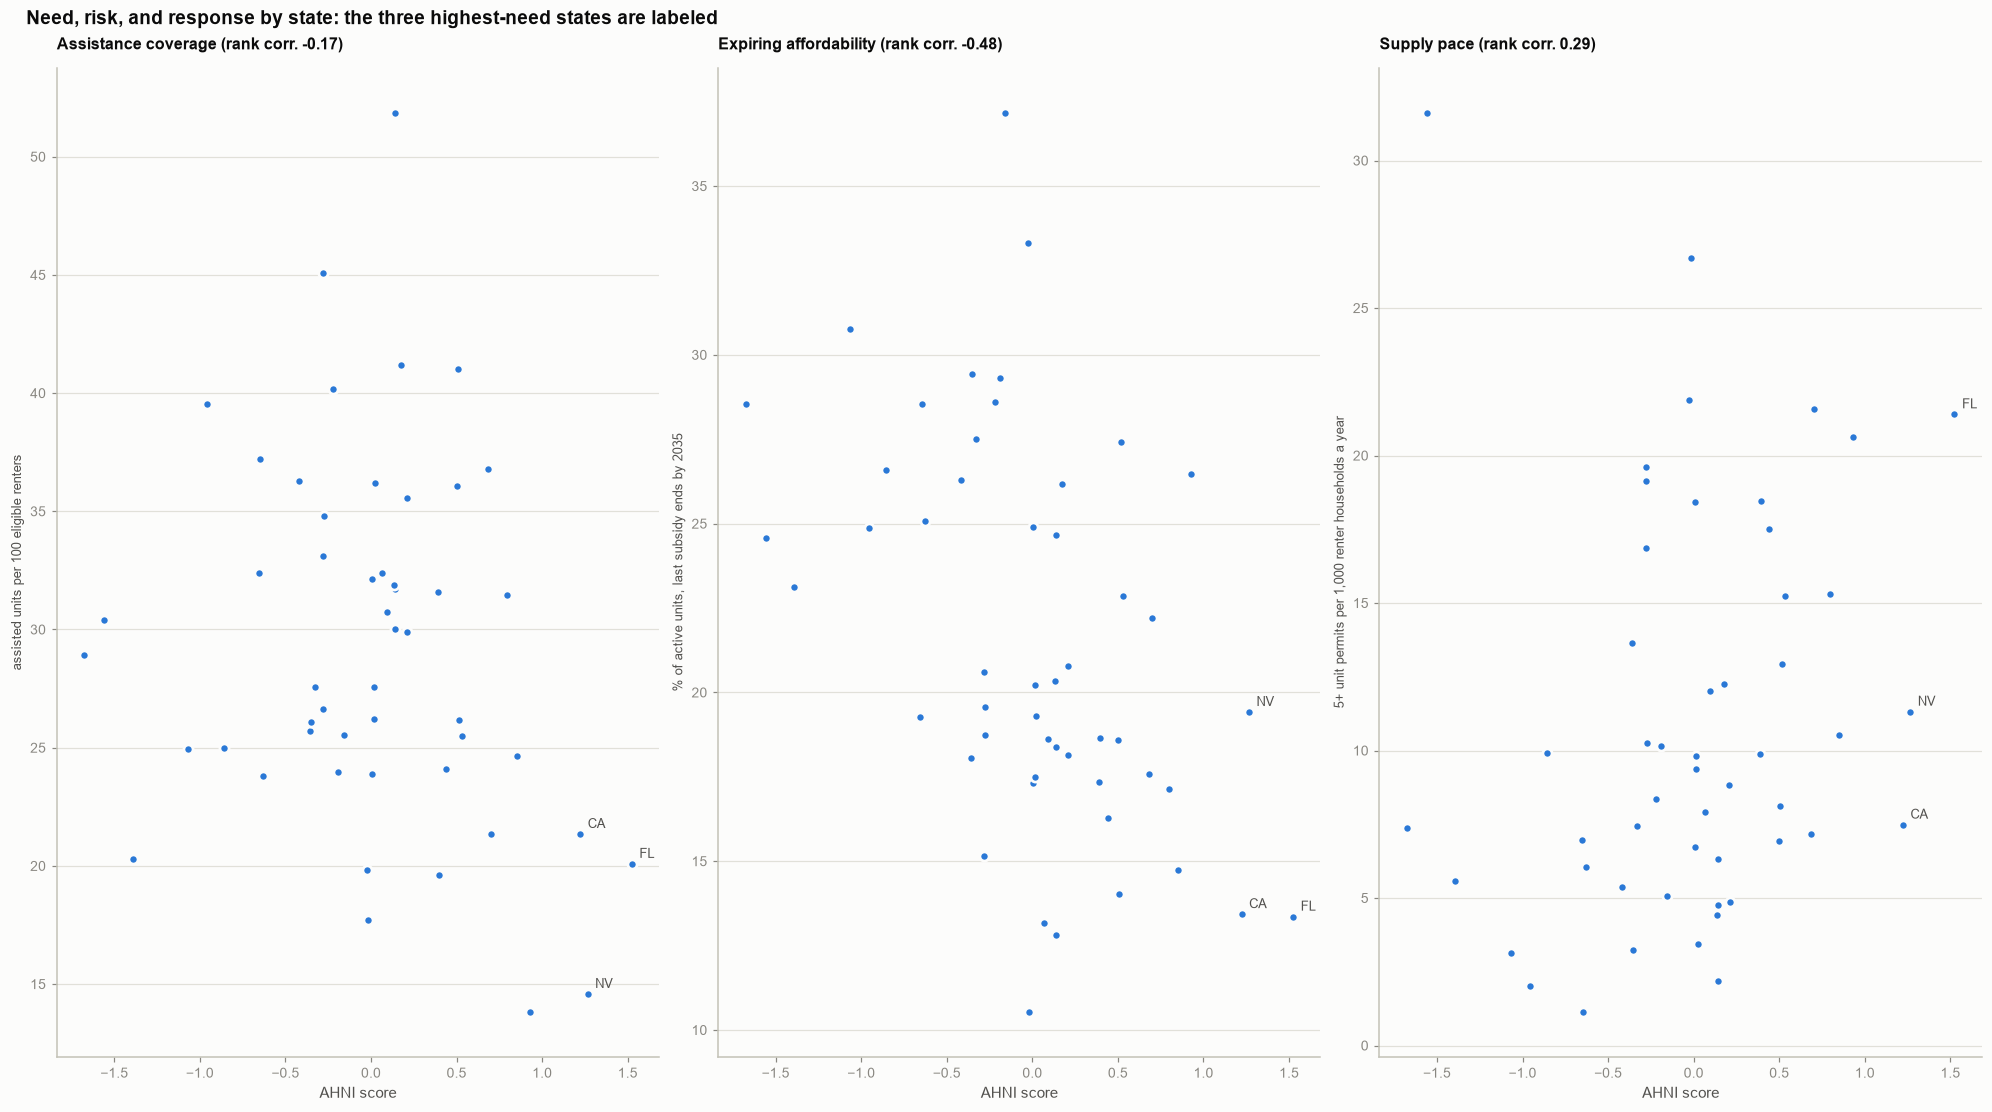

In [10]:
p22 = panel[panel.year == 2022].set_index("state_abbr")
cov_rate = 100 * p22.psh_total_units / p22.chas_renters_le50
exp_ub = snap.nhpd_pct_last_end_by_2035_ub
exp_lb = 100 * snap.nhpd_last_end_by_2035_units_lb / snap.nhpd_active_units_ub
pace = panel[panel.year.isin([2022, 2023, 2024])].groupby("state_abbr").permits_5plus_per_1000_renter_hh.mean()
hh = panel.pivot(index="state_abbr", columns="year", values="hh_renter")
new_hh = hh[2024] - hh[2021]
permits3 = panel[panel.year.isin([2022, 2023, 2024])].groupby("state_abbr").permits_5plus.sum()
per_new = (permits3 / new_hh.where(new_hh > 0)) * 1.0
policy = pd.DataFrame({"state": names, "AHNI score": score, "AHNI rank": rank,
                       "assisted units per 100 eligible renters": cov_rate,
                       "% of active NHPD units losing last subsidy by 2035 (upper)": exp_ub,
                       "(lower bound)": exp_lb,
                       "5+ unit permits per 1,000 renter hh (2022-24 mean)": pace,
                       "5+ unit permits per new renter hh, 2022-24": per_new})
policy.to_csv("outputs/tables/policy_metrics.csv")
display(policy.sort_values("AHNI rank").head(10).round(2))
print(f"states where renter households did not grow 2021 to 2024 (no ratio): {int(new_hh.le(0).sum())}")

fig, axes = plt.subplots(1, 3, figsize=(18, 10))
specs = [(cov_rate, "assisted units per 100 eligible renters", "Assistance coverage"),
         (exp_ub, "% of active units, last subsidy ends by 2035", "Expiring affordability"),
         (pace, "5+ unit permits per 1,000 renter households a year", "Supply pace")]
for ax, (yv, ylab, ttl) in zip(axes, specs):
    d = pd.DataFrame({"x": score, "y": yv}).dropna()
    ax.scatter(d.x, d.y, s=36, color=SERIES[0], edgecolor=SURFACE, linewidth=1.8, zorder=3)
    r_ = d.x.corr(d.y, method="spearman")
    ax.set_title(f"{ttl} (rank corr. {r_:.2f})", fontsize=10.5)
    ax.set_xlabel("AHNI score")
    ax.set_ylabel(ylab, fontsize=8.5)
    ax.grid(axis="x", visible=False)
    for st in list(score.nlargest(3).index):
        ax.annotate(st, (d.x[st], d.y[st]), xytext=(5, 4), textcoords="offset points", fontsize=8.5, color=INK_2)
fig.suptitle("Need, risk, and response by state: the three highest-need states are labeled", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
save_figure(fig, "04_need_vs_policy_metrics")
plt.show()

## 7. Direction of change (kept apart from the level)

Change in need between 2010-12 and 2022-24 from three ACS components (severe burden, burden at 30 percent or more, rent as a
share of income), standardized and averaged. Positive means need rose. It is a separate score, not part of the headline.

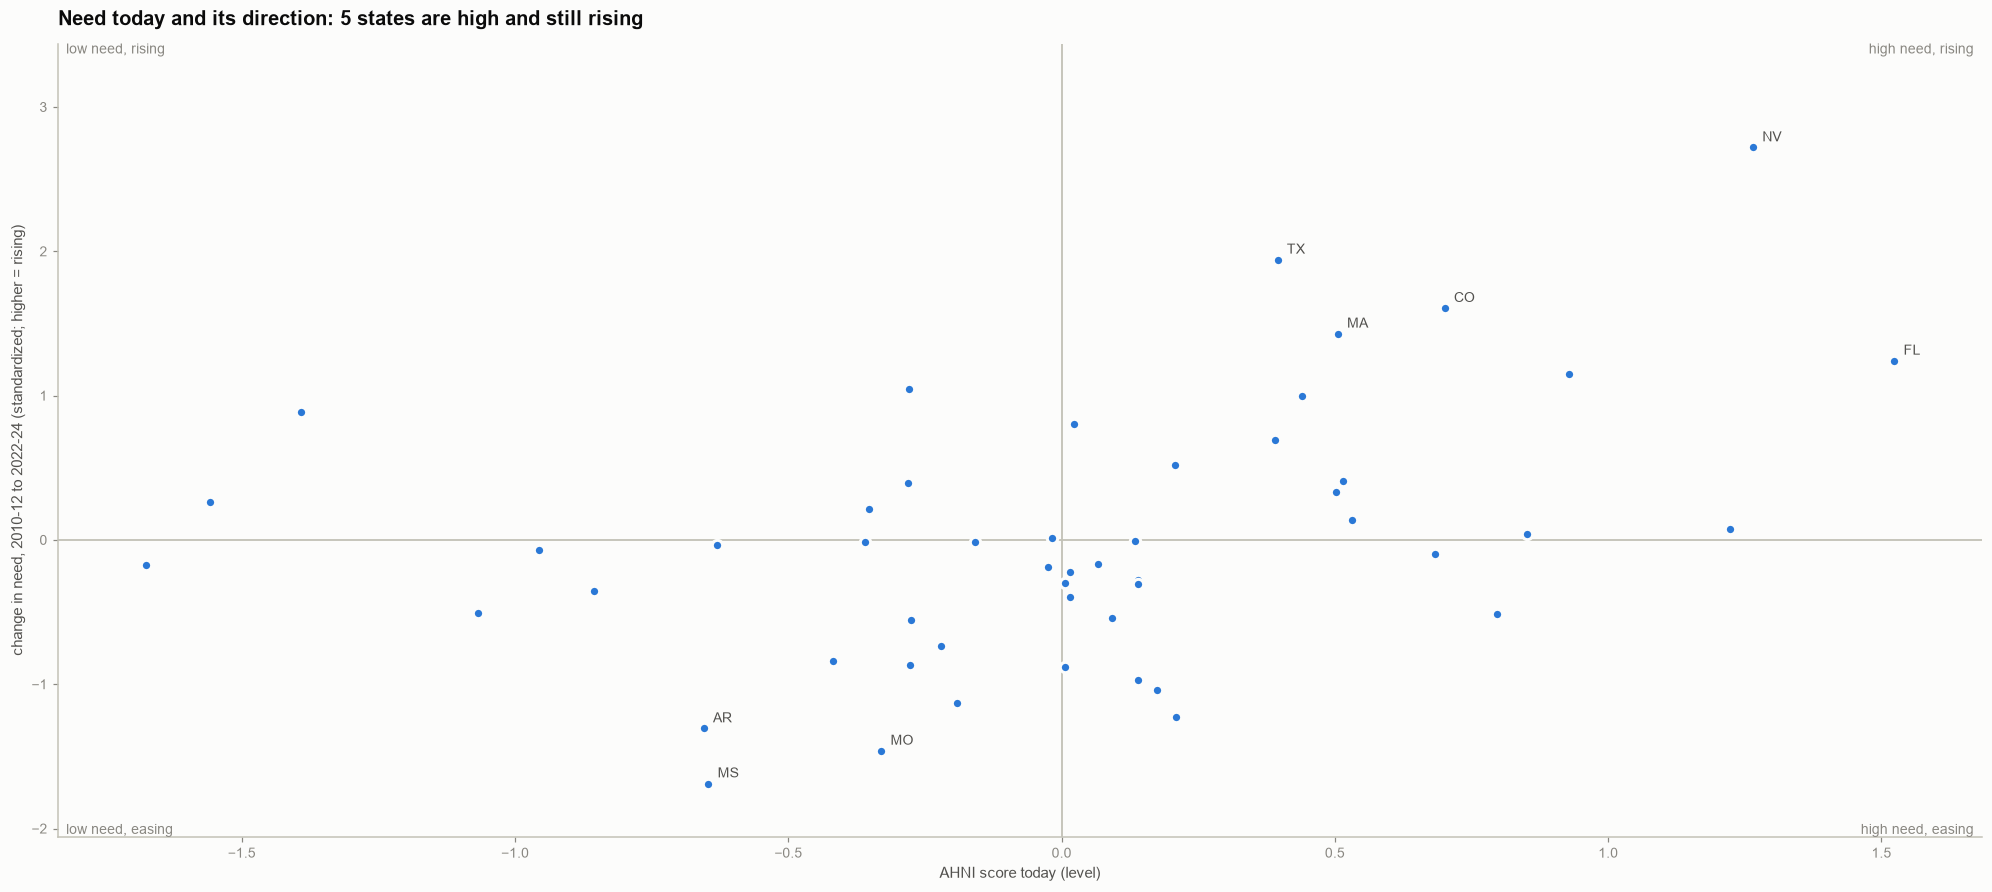

,state,AHNI rank,AHNI score,momentum
NV,Nevada,2,1.27,2.72
TX,Texas,14,0.40,1.94
CO,Colorado,7,0.70,1.61
MA,Massachusetts,11,0.51,1.43
FL,Florida,1,1.52,1.24
AZ,Arizona,4,0.93,1.15
NE,Nebraska,37,-0.28,1.05
WA,Washington,13,0.44,0.99


high need (score above 0.5) and rising (momentum above 0.5): ['AZ', 'CO', 'FL', 'MA', 'NV']


In [11]:
chg, mom = ahni.momentum(panel)
fig, ax = plt.subplots(figsize=(18, 8))
ax.axhline(0, color=BASELINE, lw=1.2, zorder=1); ax.axvline(0, color=BASELINE, lw=1.2, zorder=1)
ax.scatter(score, mom, s=46, color=SERIES[0], edgecolor=SURFACE, linewidth=2, zorder=3)
for st in list(mom.nlargest(4).index) + list(mom.nsmallest(3).index) + ["FL"]:
    ax.annotate(st, (score[st], mom[st]), xytext=(6, 4), textcoords="offset points", fontsize=9, color=INK_2)
xl, yl = ax.get_xlim(), ax.get_ylim()
yl = (yl[0] - 0.15, yl[1] + 0.5)
ax.set_ylim(yl)                                    # headroom so the corner labels clear the data
ax.text(xl[1], yl[1], "high need, rising  ", ha="right", va="top", fontsize=9, color=MUTED)
ax.text(xl[0], yl[1], "  low need, rising", ha="left", va="top", fontsize=9, color=MUTED)
ax.text(xl[1], yl[0], "high need, easing  ", ha="right", va="bottom", fontsize=9, color=MUTED)
ax.text(xl[0], yl[0], "  low need, easing", ha="left", va="bottom", fontsize=9, color=MUTED)
ax.set_xlabel("AHNI score today (level)")
ax.set_ylabel("change in need, 2010-12 to 2022-24 (standardized; higher = rising)")
ax.grid(False)
rising_hi = [s for s in score.index if score[s] > 0.5 and mom[s] > 0.5]
ax.set_title(f"Need today and its direction: {len(rising_hi)} states are high and still rising")
save_figure(fig, "04_level_vs_momentum")
plt.show()
display(pd.DataFrame({"state": names, "AHNI rank": rank, "AHNI score": score, "momentum": mom}).sort_values("momentum", ascending=False).head(8).round(2))
print("high need (score above 0.5) and rising (momentum above 0.5):", rising_hi)

## Save the ranking

In [12]:
out = pd.DataFrame({"state": names, "state_fips": pd.Series({v: k for k, v in ahni.ABBR.items()}), "ahni_score": score, "ahni_rank": rank,
                    "rank_p05": lo, "rank_p95": hi, "chance_top10": top10, "burden": dims.burden, "gap": dims.gap, "pressure": dims.pressure,
                    "momentum": mom})
for c in schemes.columns:
    out["rank: " + c] = rk[c]
out = out.join(est).join(z.add_prefix("z_")).sort_values("ahni_rank")
out.to_csv("outputs/tables/ahni_ranking.csv")
print(f"saved outputs/tables/ahni_ranking.csv ({out.shape[0]} states, {out.shape[1]} columns) and policy_metrics.csv")

saved outputs/tables/ahni_ranking.csv (51 states, 36 columns) and policy_metrics.csv


## Findings

1. **Five of the seven components measure the same thing; two do not.** Severe burden (ACS), burden at 30 percent or more,
   CHAS severe burden, rent as a share of income, and affordable units per 100 extremely low income renters correlate 0.70
   to 0.95 and load 0.40 to 0.46 on the first principal component, which explains 62 percent of the variance. The rental
   vacancy rate (inverted) correlates -0.11 to -0.25 with the burden measures, and the rent-minus-income growth gap 0.07 to
   0.21. They load -0.09 and +0.09. The growth gap is also the noisiest component (between-state SD only 2.8 times its
   standard error, against 6 to 19 for the others). Vacancy and the growth gap add different information, or noise, not more
   of the same, and the index mixes them in as designed.
2. **The ranking.** Highest need: Florida, Nevada, California, Arizona, Oregon, New Jersey, Colorado, New York, Georgia, Virginia.
   Lowest: North Dakota, South Dakota, Wyoming, Alaska, West Virginia, Iowa. Florida's lead is driven by burden (+2.6) and
   pressure (+2.1); California's by the affordable-unit gap (+1.3).
3. **Sampling error leaves the top clear and the middle uncertain.** The top eight each keep their rank within two places in
   the 5th to 95th percentile of 1,000 redraws (Florida is first in every draw). Ranks 9 to 12 have only a 38 to 60 percent
   chance of being in the top ten (Georgia 60, Virginia 45, Massachusetts 42, Connecticut 38). 14 states, mostly small ones in
   the middle (Vermont, Delaware, Rhode Island, New Hampshire), have rank intervals 10 or more places wide, up to 17.
4. **The ranking is robust to weights, less so to which components are in.** Rank correlations across the four weightings are
   0.88 to 0.99; the principal-component version differs most and keeps 7 of the headline top ten, against 9 for the expert
   weights and for equal weight per component. Dropping any one burden component leaves the rank correlation at 0.99 or
   higher, because the three overlap. Dropping the affordable-unit gap, rent to income, or the growth gap moves a state by up to
   17 or 18 places (rank correlation 0.91 to 0.95). Hawaii is the most sensitive (a 18-place spread across weightings) because
   its rent growth fell behind income growth (z = -2.6) while its burden is high.
5. **Validation against homelessness is modest.** The index and the point-in-time rate (2022 and 2023 means, both complete
   years) have a rank correlation of 0.34 (0.38 without DC). Rent as a share of income tracks it best (0.41); severe burden
   only 0.16; the growth gap not at all (-0.02). Florida, ranked first, has about 13 homeless per 10,000, while DC and Vermont
   are high despite middling need. Homelessness depends on climate, shelter capacity, and counting practice as well as rent, so
   this is a partial validation, not a failure, but it means the index should not be sold as a homelessness predictor.
6. **High-need states are not better covered, and are building more.** Ranking against the other policy metrics: assistance
   coverage -0.17 (the ten highest-need states have a median 23 assisted units per 100 eligible renters against 30 for the other
   41; 8 of the 10 are below the all-state median of 29; the lowest are Arizona 14, Nevada 15, Utah 18, Texas 20, Idaho 20);
   expiring affordability -0.48 (higher-need states have a somewhat smaller share of active units losing their last subsidy by
   2035: median 18.5 against 20.4 percent); supply pace +0.29 (14.1 against 8.1 permitted multifamily units per 1,000 renter
   households a year). Building is concentrated where need is highest but has not offset it.
7. **Direction of change.** Five states are both high-need (score above 0.5) and rising (momentum above 0.5): Nevada (momentum
   2.7, the highest), Florida, Arizona, Colorado, and Massachusetts. Texas (1.9) is just below the level cutoff. The most
   improved are Mississippi, Missouri, Arkansas, and Michigan.

**What this means for the plan**

* **Report the ranking with intervals, never as a bare list.** The top eight are firm; positions 9 to 25 are not, and the
  small middle states can move ten places on sampling error alone.
* **Do not equate need with the homelessness count.** The index and the PIT rate share only a moderate rank correlation.
* **The vacancy rate and the rent-growth gap are the weakest components.** Section 5 above shows how much each matters; a
  defensible alternative index would drop them. The headline keeps them as designed, with the alternatives shown as
  sensitivity, and the choice is flagged for review.
* **For the models,** the AHNI is not a target. The target remains annual severe burden; the AHNI components that are not the
  target (CHAS gap, vacancy, rent to income) may be used as predictors only if they are known at the forecast origin, which
  the CHAS snapshots are not.

**Caveats.** The CHAS and ACS margins of error are taken as accurate and annual samples as independent. The expert weights
(50, 30, 20) are the analyst's proposal, not an expert panel's. The homelessness validation uses total counts, which include
partly incomplete unsheltered counts in some states for other years.